In [1]:
import os
import io
import gzip
import struct
import time
import copy
import random
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torchvision.models import vgg16, alexnet, VGG16_Weights, AlexNet_Weights
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if device.type != "cuda":
    raise RuntimeError("Activer GPU dans les paramètres de Kaggle avant de continuer.")

torch.backends.cudnn.benchmark = True
WORKDIR = Path("/kaggle/working")
FIGDIR = WORKDIR / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
NUM_WORKERS = 2

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Nombre de GPU disponibles:", torch.cuda.device_count())

PyTorch: 2.11.0+cu128
TorchVision: 0.26.0+cu128
GPU: Tesla T4
Nombre de GPU disponibles: 2


In [2]:
input_root = Path("/kaggle/input")
all_input_files = sorted(p for p in input_root.rglob("*") if p.is_file())

def find_idx_file(split, kind):
    prefix = f"{split}-{kind}"
    candidates = [
        p for p in all_input_files
        if p.name.lower().startswith(prefix) and "ubyte" in p.name.lower()
    ]
    if not candidates:
        raise FileNotFoundError(f"Fichier MNIST introuvable: {prefix}. Ajouter hojjatk/mnist-dataset dans Add Input.")
    return candidates[0]

def read_idx(path):
    if str(path).lower().endswith(".gz"):
        with gzip.open(path, "rb") as f:
            buffer = f.read()
    else:
        buffer = path.read_bytes()
    magic = struct.unpack(">I", buffer[:4])[0]
    if magic == 2051:
        count, rows, cols = struct.unpack(">III", buffer[4:16])
        return np.frombuffer(buffer, dtype=np.uint8, offset=16).reshape(count, rows, cols).copy()
    if magic == 2049:
        count = struct.unpack(">I", buffer[4:8])[0]
        return np.frombuffer(buffer, dtype=np.uint8, offset=8).reshape(count).copy()
    raise ValueError(f"Format IDX non reconnu: {path} (magic={magic})")

train_images = read_idx(find_idx_file("train", "images"))
train_labels = read_idx(find_idx_file("train", "labels"))
test_images = read_idx(find_idx_file("t10k", "images"))
test_labels = read_idx(find_idx_file("t10k", "labels"))

assert len(train_images) == len(train_labels)
assert len(test_images) == len(test_labels)
assert train_images.shape[1:] == (28, 28)

print("MNIST train:", train_images.shape, train_labels.shape)
print("MNIST test:", test_images.shape, test_labels.shape)
print("Classes:", np.unique(train_labels))

MNIST train: (60000, 28, 28) (60000,)
MNIST test: (10000, 28, 28) (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


Training: 60000
Test: 10000


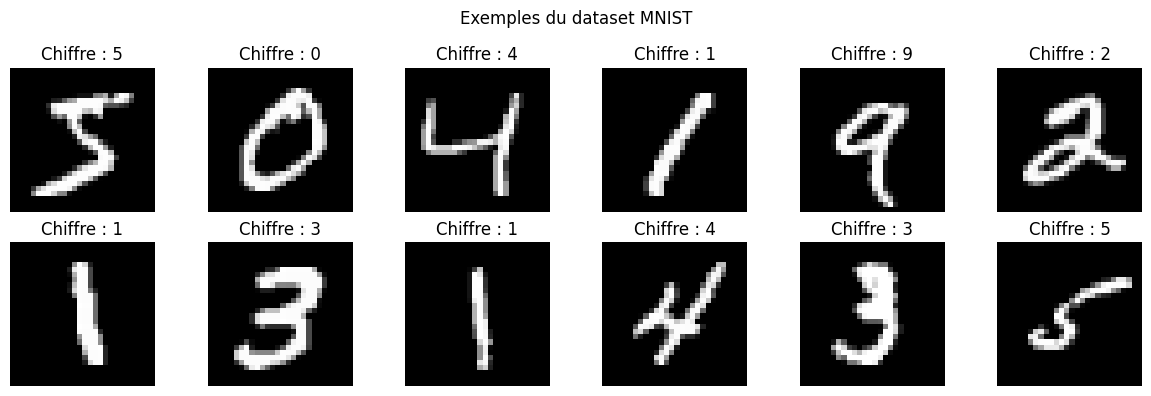

Distribution train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Distribution test: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


In [3]:
X_train_raw, y_train = train_images, train_labels
X_test_raw, y_test = test_images, test_labels

assert len(y_train) == 60000
assert len(y_test) == 10000

print("Training:", len(y_train))
print("Test:", len(y_test))

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_raw[i], cmap="gray")
    ax.set_title(f"Chiffre : {int(y_train[i])}")
    ax.axis("off")
plt.suptitle("Exemples du dataset MNIST")
plt.tight_layout()
plt.savefig(FIGDIR / "mnist_exemples.png", dpi=160, bbox_inches="tight")
plt.show()

print("Distribution train:", np.bincount(y_train, minlength=10))
print("Distribution test:", np.bincount(y_test, minlength=10))

In [4]:
class MNISTImageDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        from PIL import Image
        image = Image.fromarray(self.images[index], mode="L")
        return self.transform(image), int(self.labels[index])

cnn_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

pretrained_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def make_classification_loaders(transform, batch_size):
    train_set = MNISTImageDataset(X_train_raw, y_train, transform)
    test_set = MNISTImageDataset(X_test_raw, y_test, transform)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    return train_loader, test_loader

cnn_train_loader, cnn_test_loader = make_classification_loaders(cnn_transform, 64)
pre_train_loader, pre_test_loader = make_classification_loaders(pretrained_transform, 16)

results = []
histories = {}
confusions = {}
print("DataLoaders prêts")
print("CNN train:", len(cnn_train_loader.dataset), "CNN test:", len(cnn_test_loader.dataset))
print("Pretrained train:", len(pre_train_loader.dataset), "Pretrained test:", len(pre_test_loader.dataset))

DataLoaders prêts
CNN train: 60000 CNN test: 10000
Pretrained train: 60000 Pretrained test: 10000


In [5]:
def evaluate_classifier(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    total_count = 0
    true_labels = []
    predicted_labels = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
            total_count += len(labels)
            true_labels.extend(labels.cpu().tolist())
            predicted_labels.extend(logits.argmax(1).cpu().tolist())

    accuracy = accuracy_score(true_labels, predicted_labels)
    macro_f1 = f1_score(true_labels, predicted_labels, labels=list(range(10)), average="macro", zero_division=0)
    return {
        "loss": total_loss / total_count,
        "accuracy": accuracy,
        "f1": macro_f1,
        "y_true": np.array(true_labels),
        "y_pred": np.array(predicted_labels)
    }

def train_classifier(name, model, train_loader, epochs, lr):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=1e-4
    )
    history = {"train_loss": [], "train_accuracy": [], "train_f1": []}

    torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_count = 0
        train_true = []
        train_pred = []

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
            total_count += len(labels)
            train_true.extend(labels.cpu().tolist())
            train_pred.extend(logits.detach().argmax(1).cpu().tolist())

        train_loss = total_loss / total_count
        train_acc = accuracy_score(train_true, train_pred)
        train_f1 = f1_score(train_true, train_pred, labels=list(range(10)), average="macro", zero_division=0)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["train_f1"].append(train_f1)

        print(f"{name} | Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train F1: {train_f1:.4f} | Images: {total_count}")

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    history["epochs"] = epochs
    history["training_time"] = elapsed
    histories[name] = history
    return model, history

def register_classifier(name, model, history, test_loader):
    metrics = evaluate_classifier(model, test_loader)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    results.append({
        "Model": name,
        "Accuracy": metrics["accuracy"],
        "Macro F1": metrics["f1"],
        "Train Loss": history["train_loss"][-1],
        "Test Loss": metrics["loss"],
        "Training Time (s)": history["training_time"],
        "Epochs": history["epochs"],
        "Trainable Parameters": trainable,
        "Loss Type": "CrossEntropy"
    })
    confusions[name] = confusion_matrix(metrics["y_true"], metrics["y_pred"], labels=list(range(10)))
    torch.save({"model_state_dict": model.state_dict(), "epochs": history["epochs"]}, WORKDIR / f"{name.lower().replace(' ', '_').replace('-', '_')}.pth")
    print(f"{name} | Test Accuracy: {metrics['accuracy']:.4f} | Macro F1: {metrics['f1']:.4f} | Test Loss: {metrics['loss']:.4f} | Temps: {history['training_time']:.1f}s")
    print(classification_report(metrics["y_true"], metrics["y_pred"], labels=list(range(10)), zero_division=0))
    model.cpu()
    torch.cuda.empty_cache()
    return metrics

def plot_history(name):
    h = histories[name]
    x = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(x, h["train_loss"], label="Train Loss")
    ax[0].set_title(f"{name} - Loss")
    ax[0].set_xlabel("Epoch")
    ax[0].legend()
    if h.get("train_accuracy"):
        ax[1].plot(x, h["train_accuracy"], label="Train Accuracy")
        ax[1].plot(x, h["train_f1"], label="Train Macro F1")
        ax[1].legend()
    ax[1].set_title(f"{name} - Training")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylim(0, 1)
    plt.tight_layout()
    plt.savefig(FIGDIR / f"{name.lower().replace(' ', '_').replace('-', '_')}_courbes.png", dpi=160, bbox_inches="tight")
    plt.show()

In [6]:
class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn_model = MNISTCNN()
print(cnn_model)
print("Paramètres:", sum(p.numel() for p in cnn_model.parameters()))

MNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Paramètres: 421834


CNN | Epoch 1/5 | Train Loss: 0.1537 | Train Acc: 0.9524 | Train F1: 0.9520 | Images: 60000
CNN | Epoch 2/5 | Train Loss: 0.0653 | Train Acc: 0.9802 | Train F1: 0.9801 | Images: 60000
CNN | Epoch 3/5 | Train Loss: 0.0517 | Train Acc: 0.9847 | Train F1: 0.9846 | Images: 60000
CNN | Epoch 4/5 | Train Loss: 0.0436 | Train Acc: 0.9865 | Train F1: 0.9864 | Images: 60000
CNN | Epoch 5/5 | Train Loss: 0.0366 | Train Acc: 0.9889 | Train F1: 0.9888 | Images: 60000
CNN | Test Accuracy: 0.9911 | Macro F1: 0.9910 | Test Loss: 0.0286 | Temps: 46.4s
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99  

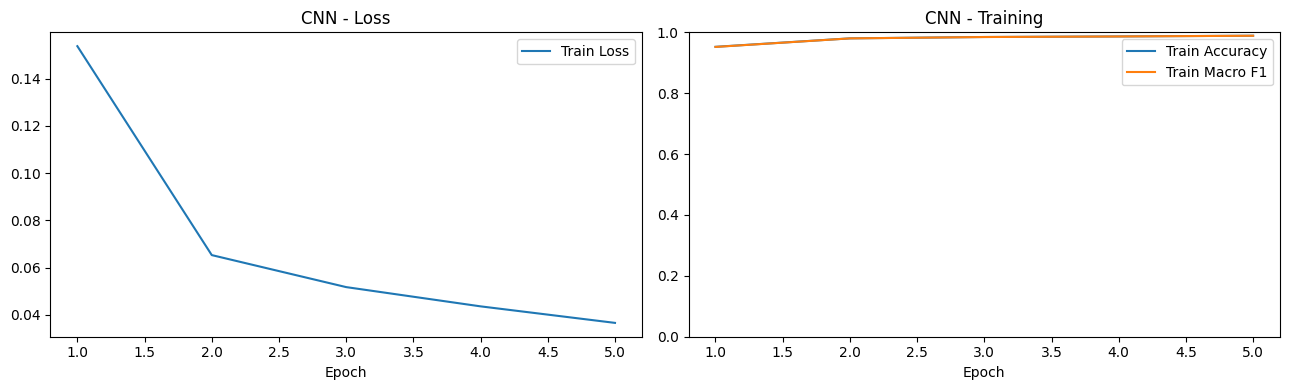

In [7]:
cnn_model, cnn_history = train_classifier(
    "CNN",
    cnn_model,
    cnn_train_loader,
    epochs=5,
    lr=0.001
)
cnn_metrics = register_classifier("CNN", cnn_model, cnn_history, cnn_test_loader)
plot_history("CNN")

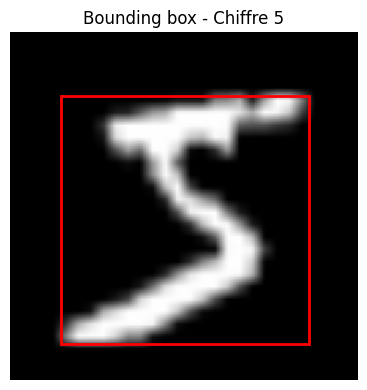

Detection training samples: 60000
Detection test samples: 10000


In [8]:
class MNISTDetectionDataset(Dataset):
    def __init__(self, images, labels, image_size=128):
        self.images = images
        self.labels = labels
        self.image_size = image_size
        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        from PIL import Image
        array = self.images[index]
        image = Image.fromarray(array, mode="L")
        image = self.transform(image).repeat(3, 1, 1)
        ys, xs = np.where(array > 20)

        if len(xs) == 0:
            x1, y1, x2, y2 = 1, 1, 27, 27
        else:
            x1, y1 = int(xs.min()), int(ys.min())
            x2, y2 = int(xs.max()) + 1, int(ys.max()) + 1

        scale = self.image_size / 28.0
        box = torch.tensor([[x1 * scale, y1 * scale, x2 * scale, y2 * scale]], dtype=torch.float32)
        digit_label = int(self.labels[index]) + 1
        area = (box[:, 2] - box[:, 0]) * (box[:, 3] - box[:, 1])

        target = {
            "boxes": box,
            "labels": torch.tensor([digit_label], dtype=torch.int64),
            "image_id": torch.tensor([index]),
            "area": area,
            "iscrowd": torch.zeros(1, dtype=torch.int64)
        }
        return image, target

def detection_collate(batch):
    return tuple(zip(*batch))

det_train_set = MNISTDetectionDataset(X_train_raw, y_train)
det_test_set = MNISTDetectionDataset(X_test_raw, y_test)

det_train_loader = DataLoader(det_train_set, batch_size=4, shuffle=True, num_workers=NUM_WORKERS, collate_fn=detection_collate, pin_memory=True)
det_test_loader = DataLoader(det_test_set, batch_size=8, shuffle=False, num_workers=NUM_WORKERS, collate_fn=detection_collate, pin_memory=True)

image, target = det_train_set[0]
plt.figure(figsize=(4, 4))
plt.imshow(image[0].numpy(), cmap="gray")
x1, y1, x2, y2 = target["boxes"][0].numpy()
plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2, edgecolor="red"))
plt.title(f"Bounding box - Chiffre {int(target['labels'][0])-1}")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIGDIR / "mnist_bounding_box.png", dpi=160, bbox_inches="tight")
plt.show()
print("Detection training samples:", len(det_train_set))
print("Detection test samples:", len(det_test_set))

In [9]:
try:
    detector = fasterrcnn_mobilenet_v3_large_320_fpn(
        weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT,
        trainable_backbone_layers=0,
        box_detections_per_img=1
    )
except Exception as e:
    raise RuntimeError("Poids Faster R-CNN indisponibles. Activer Internet dans Kaggle ou ajouter les poids pré-entraînés au cache.") from e

in_features = detector.roi_heads.box_predictor.cls_score.in_features
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features, 11)
detector = detector.to(device)

print("Faster R-CNN prêt")
print("Nombre de classes avec fond:", detector.roi_heads.box_predictor.cls_score.out_features)

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 175MB/s] 


Faster R-CNN prêt
Nombre de classes avec fond: 11


Faster R-CNN | Epoch 1/2 | Train Loss: 0.5279 | Images: 60000
Faster R-CNN | Epoch 2/2 | Train Loss: 0.3141 | Images: 60000
Faster R-CNN Test Accuracy: 0.984
Faster R-CNN Test Macro F1: 0.9839
Faster R-CNN Test Loss: 0.3348
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      1.00      0.99      1032
           3       1.00      0.99      1.00      1010
           4       1.00      0.90      0.95       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       1.00      0.99      1.00       974
           9       0.91      1.00      0.95      1009

    accuracy                           0.98     10000
   macro avg       0.99      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



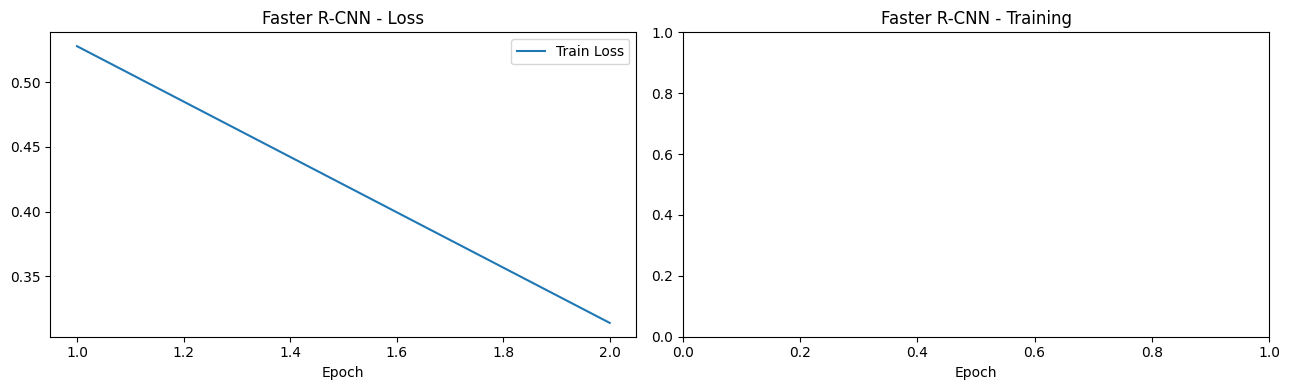

In [10]:
def evaluate_detector(model, loader):
    model.eval()
    true_labels = []
    predicted_labels = []

    with torch.inference_mode():
        for images, targets in loader:
            images = [img.to(device, non_blocking=True) for img in images]
            outputs = model(images)

            for out, tgt in zip(outputs, targets):
                true_labels.append(int(tgt["labels"][0]) - 1)
                predicted_labels.append(int(out["labels"][0]) - 1 if len(out["labels"]) else -1)

    accuracy = accuracy_score(true_labels, predicted_labels)
    macro_f1 = f1_score(true_labels, predicted_labels, labels=list(range(10)), average="macro", zero_division=0)
    return {
        "accuracy": accuracy,
        "f1": macro_f1,
        "y_true": np.array(true_labels),
        "y_pred": np.array(predicted_labels)
    }

def evaluate_detector_loss(model, loader):
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    total_loss = 0.0
    total_count = 0

    with torch.no_grad():
        for images, targets in loader:
            images = [image.to(device, non_blocking=True) for image in images]
            targets = [{k: v.to(device, non_blocking=True) for k, v in target.items()} for target in targets]
            losses = model(images, targets)
            loss = sum(losses.values())
            total_loss += loss.item() * len(images)
            total_count += len(images)

    model.eval()
    return total_loss / total_count

def train_detector(model, epochs=2, lr=0.0002):
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=1e-4
    )
    history = {"train_loss": []}

    torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total_count = 0

        for images, targets in det_train_loader:
            images = [img.to(device, non_blocking=True) for img in images]
            targets = [{k: v.to(device, non_blocking=True) for k, v in target.items()} for target in targets]
            optimizer.zero_grad(set_to_none=True)
            losses = model(images, targets)
            loss = sum(value for value in losses.values())
            if not torch.isfinite(loss):
                raise RuntimeError("Loss non finie dans Faster R-CNN")
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(images)
            total_count += len(images)

        train_loss = running_loss / total_count
        history["train_loss"].append(train_loss)
        print(f"Faster R-CNN | Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Images: {total_count}")

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    history["epochs"] = epochs
    history["training_time"] = elapsed
    return model, history

detector, detector_history = train_detector(detector, epochs=2, lr=0.0002)
histories["Faster R-CNN"] = detector_history

detector_metrics = evaluate_detector(detector, det_test_loader)
detector_test_loss = evaluate_detector_loss(detector, det_test_loader)
results.append({
    "Model": "Faster R-CNN",
    "Accuracy": detector_metrics["accuracy"],
    "Macro F1": detector_metrics["f1"],
    "Train Loss": detector_history["train_loss"][-1],
    "Test Loss": detector_test_loss,
    "Training Time (s)": detector_history["training_time"],
    "Epochs": detector_history["epochs"],
    "Trainable Parameters": sum(p.numel() for p in detector.parameters() if p.requires_grad),
    "Loss Type": "Detection (RPN + ROI)"
})
confusions["Faster R-CNN"] = confusion_matrix(
    detector_metrics["y_true"], detector_metrics["y_pred"], labels=list(range(10)) + [-1]
)
torch.save({"model_state_dict": detector.state_dict(), "epochs": detector_history["epochs"]}, WORKDIR / "faster_rcnn_mnist.pth")

print("Faster R-CNN Test Accuracy:", round(detector_metrics["accuracy"], 4))
print("Faster R-CNN Test Macro F1:", round(detector_metrics["f1"], 4))
print("Faster R-CNN Test Loss:", round(detector_test_loss, 4))
print(classification_report(detector_metrics["y_true"], detector_metrics["y_pred"], labels=list(range(10)), zero_division=0))

plot_history("Faster R-CNN")
detector.cpu()
del detector
gc.collect()
torch.cuda.empty_cache()

,Model,Accuracy,Macro F1,Train Loss,Test Loss,Training Time (s),Epochs,Loss Type
0,CNN,0.9911,0.9910,0.0366,0.0286,46.4399,5,CrossEntropy
1,Faster R-CNN,0.9840,0.9839,0.3141,0.3348,1638.0305,2,Detection (RPN + ROI)


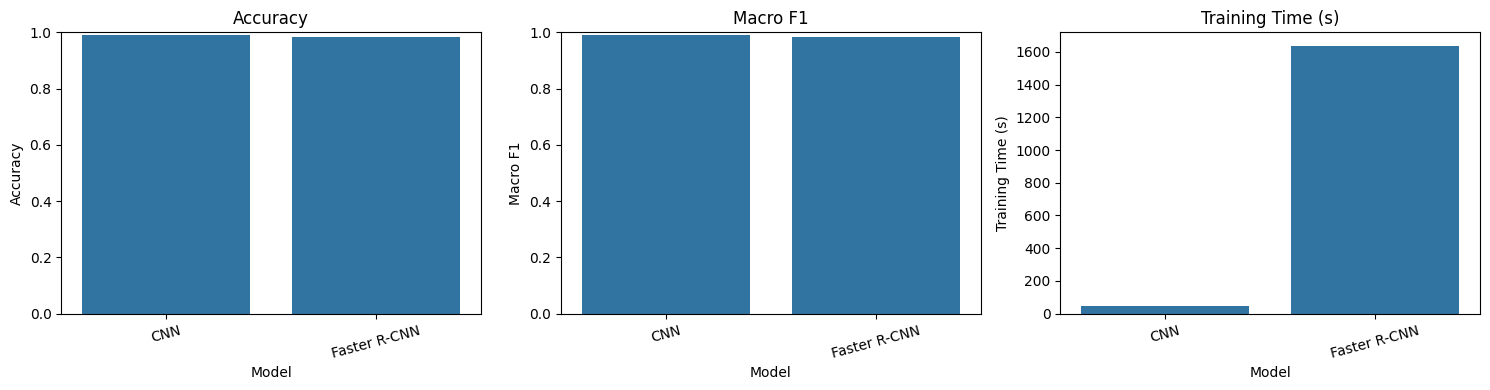

In [11]:
comparison_two = pd.DataFrame(results)
display(comparison_two[["Model", "Accuracy", "Macro F1", "Train Loss", "Test Loss", "Training Time (s)", "Epochs", "Loss Type"]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Accuracy", "Macro F1", "Training Time (s)"]):
    sns.barplot(data=comparison_two, x="Model", y=metric, ax=ax)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=15)
    if metric != "Training Time (s)":
        ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(FIGDIR / "comparaison_cnn_faster_rcnn.png", dpi=160, bbox_inches="tight")
plt.show()

In [12]:
try:
    vgg_model = vgg16(weights=VGG16_Weights.DEFAULT)
except Exception as e:
    raise RuntimeError("Poids VGG16 indisponibles. Activer Internet dans Kaggle ou ajouter le checkpoint VGG16 pré-entraîné au cache.") from e

for parameter in vgg_model.features.parameters():
    parameter.requires_grad = False

for parameter in vgg_model.features[24:].parameters():
    parameter.requires_grad = True

vgg_model.classifier = nn.Sequential(
    nn.Linear(512 * 7 * 7, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 10)
)

print("VGG16 paramètres entraînables:", sum(p.numel() for p in vgg_model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 217MB/s]  


VGG16 paramètres entraînables: 13504778


VGG16 | Epoch 1/3 | Train Loss: 0.0641 | Train Acc: 0.9817 | Train F1: 0.9816 | Images: 60000
VGG16 | Epoch 2/3 | Train Loss: 0.0280 | Train Acc: 0.9920 | Train F1: 0.9920 | Images: 60000
VGG16 | Epoch 3/3 | Train Loss: 0.0185 | Train Acc: 0.9949 | Train F1: 0.9948 | Images: 60000
VGG16 | Test Accuracy: 0.9943 | Macro F1: 0.9942 | Test Loss: 0.0223 | Temps: 1143.7s
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       1.00      1.00      1.00      1135
           2       1.00      0.99      1.00      1032
           3       1.00      1.00      1.00      1010
           4       0.99      1.00      0.99       982
           5       1.00      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.99      1.00      0.99      1028
           8       0.99      0.99      0.99       974
           9       1.00      0.99      0.99      1009

    accuracy                        

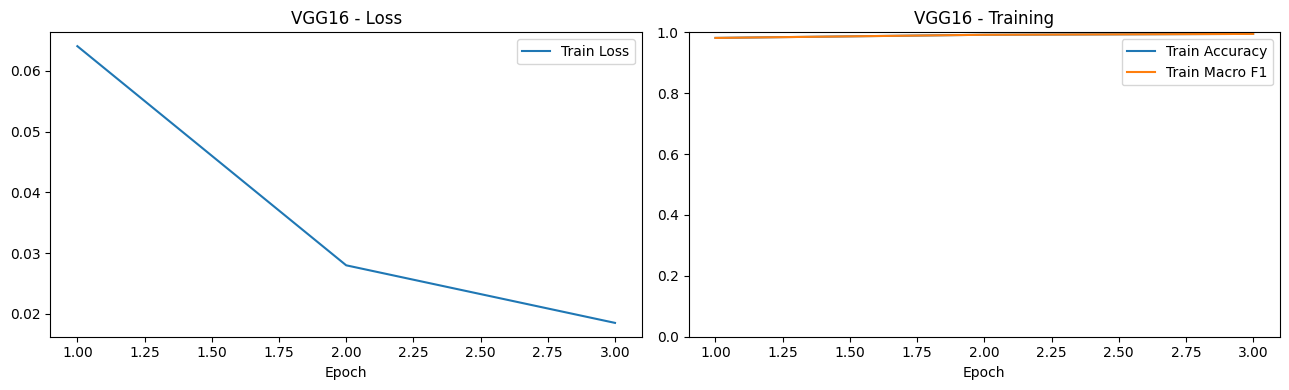

In [13]:
vgg_model, vgg_history = train_classifier(
    "VGG16",
    vgg_model,
    pre_train_loader,
    epochs=3,
    lr=0.0001
)
vgg_metrics = register_classifier("VGG16", vgg_model, vgg_history, pre_test_loader)
plot_history("VGG16")
del vgg_model
gc.collect()
torch.cuda.empty_cache()

In [14]:
try:
    alex_model = alexnet(weights=AlexNet_Weights.DEFAULT)
except Exception as e:
    raise RuntimeError("Poids AlexNet indisponibles. Activer Internet dans Kaggle ou ajouter le checkpoint AlexNet pré-entraîné au cache.") from e

for parameter in alex_model.features.parameters():
    parameter.requires_grad = False

for parameter in alex_model.features[-3:].parameters():
    parameter.requires_grad = True

alex_model.classifier = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(256 * 6 * 6, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 10)
)

print("AlexNet paramètres entraînables:", sum(p.numel() for p in alex_model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 214MB/s]  


AlexNet paramètres entraînables: 2952202


AlexNet | Epoch 1/3 | Train Loss: 0.0759 | Train Acc: 0.9771 | Train F1: 0.9769 | Images: 60000
AlexNet | Epoch 2/3 | Train Loss: 0.0238 | Train Acc: 0.9926 | Train F1: 0.9925 | Images: 60000
AlexNet | Epoch 3/3 | Train Loss: 0.0153 | Train Acc: 0.9953 | Train F1: 0.9953 | Images: 60000
AlexNet | Test Accuracy: 0.9941 | Macro F1: 0.9941 | Test Loss: 0.0190 | Temps: 203.5s
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       1.00      1.00      1.00      1010
           4       0.99      0.99      0.99       982
           5       1.00      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       1.00      0.99      0.99      1028
           8       0.99      1.00      1.00       974
           9       0.99      0.99      0.99      1009

    accuracy                 

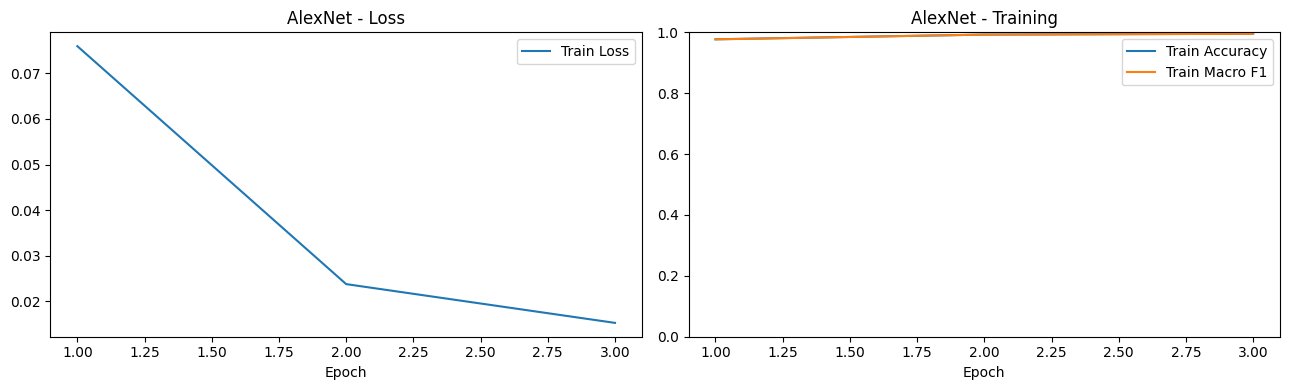

In [15]:
alex_model, alex_history = train_classifier(
    "AlexNet",
    alex_model,
    pre_train_loader,
    epochs=3,
    lr=0.0001
)
alex_metrics = register_classifier("AlexNet", alex_model, alex_history, pre_test_loader)
plot_history("AlexNet")
del alex_model
gc.collect()
torch.cuda.empty_cache()

,Model,Accuracy,Macro F1,Train Loss,Test Loss,Training Time (s),Epochs,Trainable Parameters,Loss Type
0,VGG16,0.9943,0.9942,0.0185,0.0223,1143.7491,3,13504778,CrossEntropy
1,AlexNet,0.9941,0.9941,0.0153,0.0190,203.4510,3,2952202,CrossEntropy
2,CNN,0.9911,0.9910,0.0366,0.0286,46.4399,5,421834,CrossEntropy
3,Faster R-CNN,0.9840,0.9839,0.3141,0.3348,1638.0305,2,16028802,Detection (RPN + ROI)


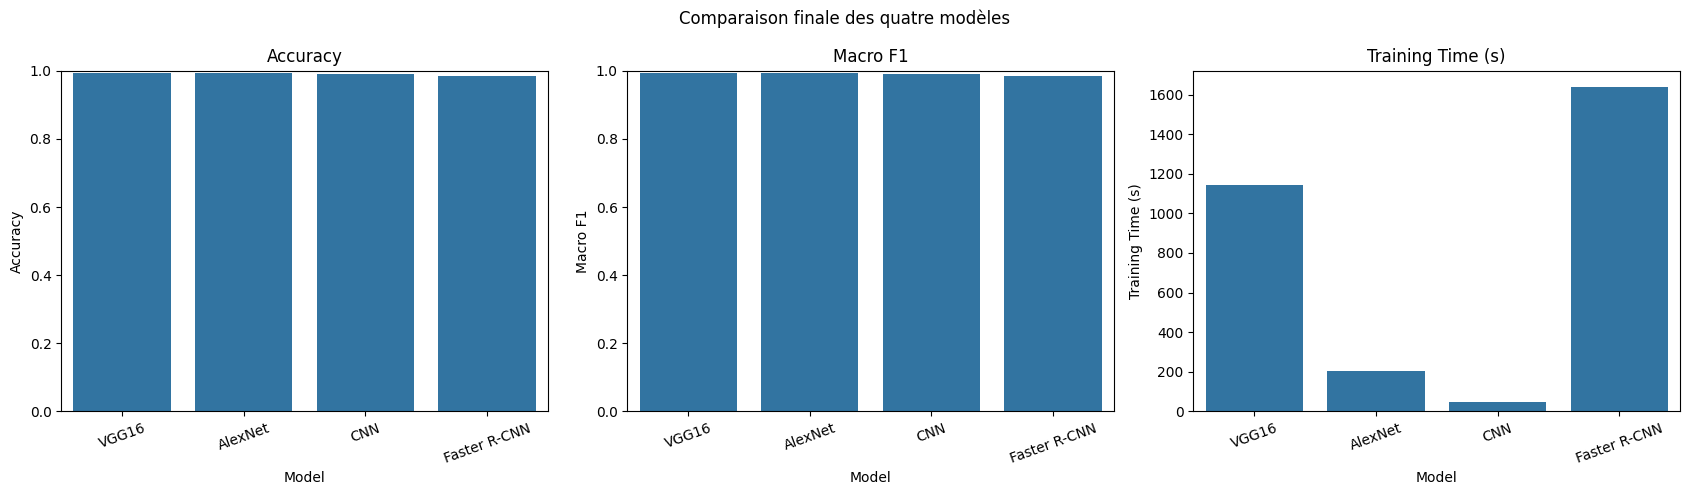

Meilleur modèle selon Macro F1 : VGG16
Accuracy : 0.9943
Macro F1 : 0.9942


In [16]:
comparison = pd.DataFrame(results)
comparison = comparison.sort_values("Macro F1", ascending=False).reset_index(drop=True)
comparison.to_csv(WORKDIR / "atelier2_part1_comparaison.csv", index=False)
display(comparison.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric in zip(axes, ["Accuracy", "Macro F1", "Training Time (s)"]):
    sns.barplot(data=comparison, x="Model", y=metric, ax=ax)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=20)
    if metric != "Training Time (s)":
        ax.set_ylim(0, 1)
plt.suptitle("Comparaison finale des quatre modèles")
plt.tight_layout()
plt.savefig(FIGDIR / "comparaison_quatre_modeles.png", dpi=160, bbox_inches="tight")
plt.show()

print("Meilleur modèle selon Macro F1 :", comparison.iloc[0]["Model"])
print("Accuracy :", round(comparison.iloc[0]["Accuracy"], 4))
print("Macro F1 :", round(comparison.iloc[0]["Macro F1"], 4))

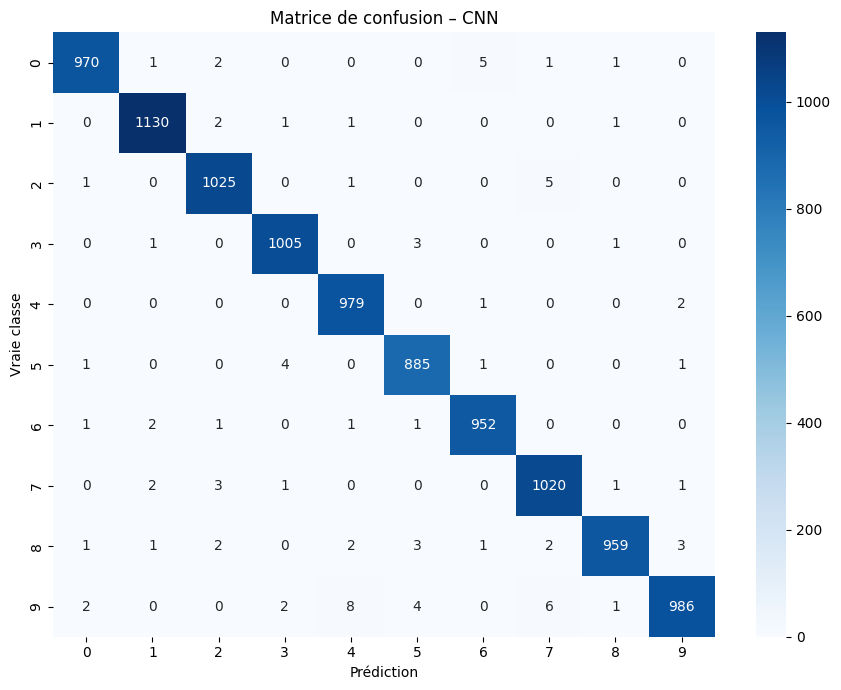

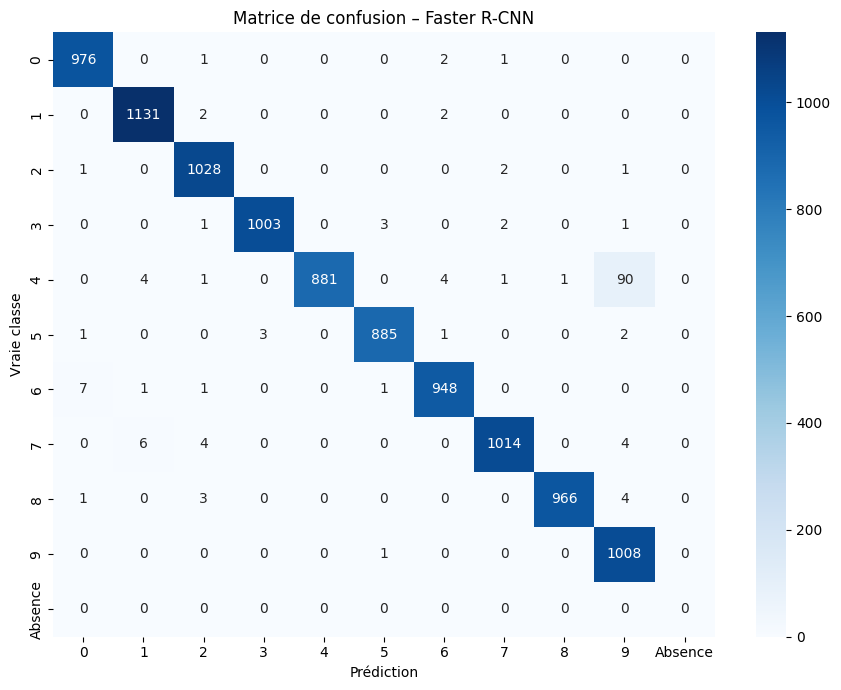

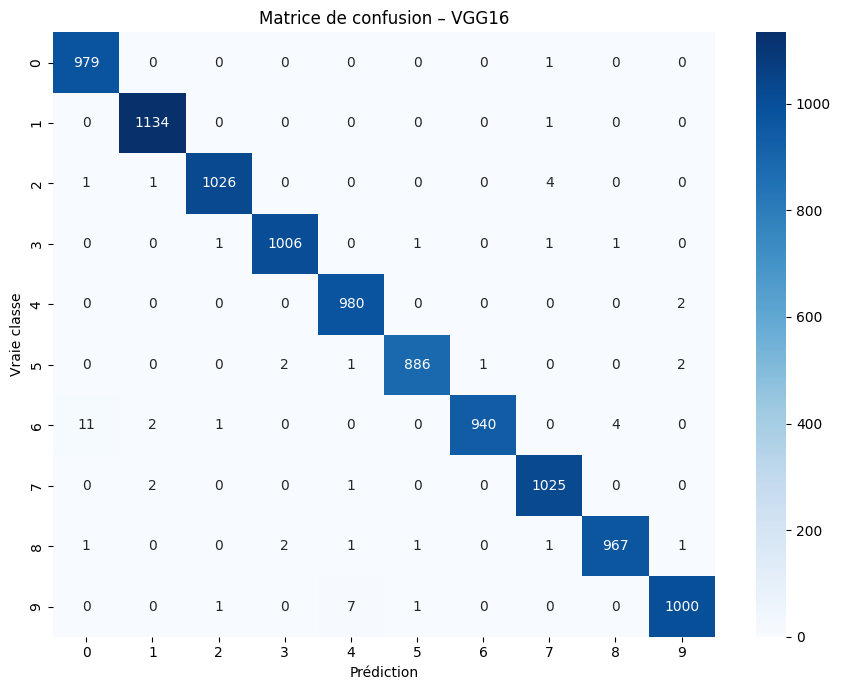

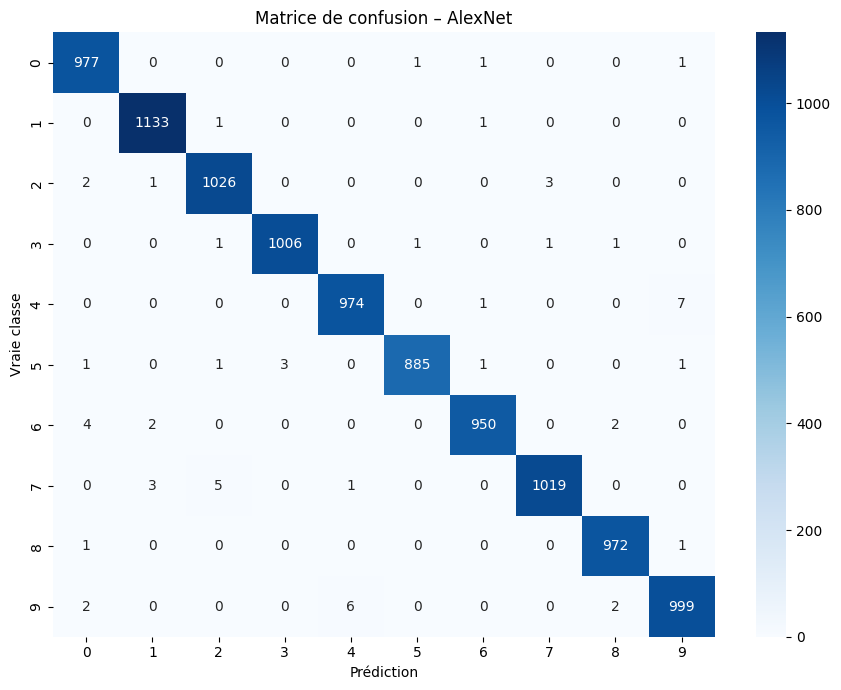

In [17]:
for name, matrix in confusions.items():
    labels = [str(i) for i in range(10)]
    if matrix.shape[1] == 11:
        labels = labels + ["Absence"]
    plt.figure(figsize=(9, 7))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )
    plt.title(f"Matrice de confusion – {name}")
    plt.xlabel("Prédiction")
    plt.ylabel("Vraie classe")
    plt.tight_layout()
    slug = name.lower().replace(" ", "_").replace("-", "_")
    plt.savefig(FIGDIR / f"confusion_{slug}.png", dpi=160, bbox_inches="tight")
    plt.show()

In [18]:
display(comparison[["Model", "Accuracy", "Macro F1", "Train Loss", "Test Loss", "Training Time (s)", "Epochs"]].round(4))

for _, row in comparison.iterrows():
    print(f"{row['Model']} | Accuracy = {row['Accuracy']:.4f} | Macro F1 = {row['Macro F1']:.4f} | Temps = {row['Training Time (s)']:.1f}s")

print("Training images par modèle:", len(y_train))
print("Test images par modèle:", len(y_test))
print("Les pertes Detection et CrossEntropy ne sont pas directement comparables.")

print("Fichiers enregistrés:")
for path in sorted(WORKDIR.glob("*.csv")):
    print(path)
for path in sorted(WORKDIR.glob("*.pth")):
    print(path)
for path in sorted(FIGDIR.glob("*.png")):
    print(path)

,Model,Accuracy,Macro F1,Train Loss,Test Loss,Training Time (s),Epochs
0,VGG16,0.9943,0.9942,0.0185,0.0223,1143.7491,3
1,AlexNet,0.9941,0.9941,0.0153,0.0190,203.4510,3
2,CNN,0.9911,0.9910,0.0366,0.0286,46.4399,5
3,Faster R-CNN,0.9840,0.9839,0.3141,0.3348,1638.0305,2


VGG16 | Accuracy = 0.9943 | Macro F1 = 0.9942 | Temps = 1143.7s
AlexNet | Accuracy = 0.9941 | Macro F1 = 0.9941 | Temps = 203.5s
CNN | Accuracy = 0.9911 | Macro F1 = 0.9910 | Temps = 46.4s
Faster R-CNN | Accuracy = 0.9840 | Macro F1 = 0.9839 | Temps = 1638.0s
Training images par modèle: 60000
Test images par modèle: 10000
Les pertes Detection et CrossEntropy ne sont pas directement comparables.
Fichiers enregistrés:
/kaggle/working/atelier2_part1_comparaison.csv
/kaggle/working/alexnet.pth
/kaggle/working/cnn.pth
/kaggle/working/faster_rcnn_mnist.pth
/kaggle/working/vgg16.pth
/kaggle/working/figures/alexnet_courbes.png
/kaggle/working/figures/cnn_courbes.png
/kaggle/working/figures/comparaison_cnn_faster_rcnn.png
/kaggle/working/figures/comparaison_quatre_modeles.png
/kaggle/working/figures/confusion_alexnet.png
/kaggle/working/figures/confusion_cnn.png
/kaggle/working/figures/confusion_faster_r_cnn.png
/kaggle/working/figures/confusion_vgg16.png
/kaggle/working/figures/faster_r_cnn_co